# ML Zoomcamp 2026 · Homework 2
## Predicting car fuel efficiency with linear regression

**Goal:** Predict `fuel_efficiency_mpg` using four car characteristics. This notebook follows the homework in order and keeps the **training**, **validation**, and **test** data separate.

**Progress:** EDA and Q1–Q2 complete; Q3 in progress. Q4–Q6 not started. This is a cleaned-up version of your work, not a completed homework solution.

## 1. Import libraries and load the data

- **Pandas (`pd`)**: read and work with tables.
- **NumPy (`np`)**: arrays, random splits, and the linear regression calculations.
- **Matplotlib / Seaborn**: plots and data exploration.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"
raw_df = pd.read_csv(url)

features = [
    'engine_displacement',
    'horsepower',
    'vehicle_weight',
    'model_year'
]
target = 'fuel_efficiency_mpg'

# Keep only the columns specified by the homework.
df = raw_df[features + [target]].copy()
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


## 2. Explore the dataset (EDA)

Before building a model, inspect the target distribution and the predictor values. A histogram helps us see whether fuel efficiency has a long tail.

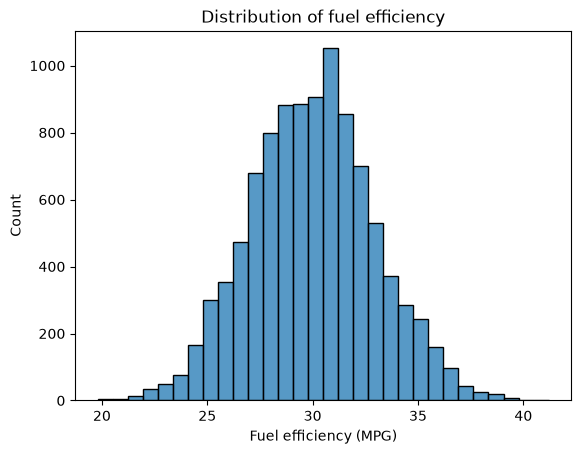

In [4]:
sns.histplot(df[target], bins=30)
plt.xlabel('Fuel efficiency (MPG)')
plt.title('Distribution of fuel efficiency')
plt.show()

### Question 1 · Which feature contains missing values?

`isna()` marks missing cells and `sum()` counts them column by column.

In [5]:
df.isna().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

**Your finding:** `horsepower` has **877** missing values (8.77% of 10,000 cars).

### Question 2 · Median horsepower

The median is the 50th percentile and is less sensitive to unusually high or low values than the mean.

In [6]:
df['horsepower'].median()

np.float64(254.0)

**Your answer:** **254 horsepower**. Inspect the distribution to understand the range and spread.

In [7]:
df['horsepower'].describe()

count    9123.000000
mean      254.446016
std        22.844613
min       171.000000
25%       239.000000
50%       254.000000
75%       270.000000
max       334.000000
Name: horsepower, dtype: float64

## 3. Split the dataset

Train on **60%**, validate modeling decisions on **20%**, and reserve the remaining **20%** for the final test. Set the seed to reproduce the same random split. **Do not calculate the imputation mean on validation or test data.**

In [8]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]].copy()
df_val = df.iloc[idx[n_train:n_train + n_val]].copy()
df_test = df.iloc[idx[n_train + n_val:]].copy()

print('Training:', len(df_train))
print('Validation:', len(df_val))
print('Test:', len(df_test))

Training: 6000
Validation: 2000
Test: 2000


## 4. Set aside the target (`y`) and features (`X`)

`X` has **four input columns**. `y` is the single value we want to predict. Keep the target out of the model's input matrix.

In [9]:
X_train = df_train[features].copy()
y_train = df_train[target].to_numpy()

X_val = df_val[features].copy()
y_val = df_val[target].to_numpy()

## 5. Question 3 · Compare two missing-value strategies

We will compare replacing missing horsepower values with **0** and with the **training-set mean**. We can't assume the more realistic value gives better predictions; the validation RMSE will tell us which worked better on this split.

### A. Replace missing values with zero

Keep these as separate feature matrices so the original split stays unchanged.

In [10]:
X_train_zero = X_train.fillna(0)
X_val_zero = X_val.fillna(0)

### Regression function from Homework 1

The function adds an intercept column and uses the ordinary least squares normal equation to estimate coefficients. It returns `w0` (intercept) and `w` (one weight per feature). `@` means matrix multiplication. This direct inverse is for learning; it assumes `X.T @ X` is invertible.

In [11]:
def train_linear_regression(X, y):
    # One intercept value for each observation.
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T @ X
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv @ X.T @ y

    return w[0], w[1:]

### Train and predict with zero imputation

**Training:** learn coefficients from `X_train_zero` and `y_train`.

**Prediction:** use those same coefficients with validation features. `.to_numpy()` converts the Pandas table into a NumPy array.

In [12]:
w0_zero, w_zero = train_linear_regression(
    X_train_zero.to_numpy(), y_train
)

y_pred_zero = w0_zero + X_val_zero.to_numpy() @ w_zero

In [13]:
mse_zero = np.mean((y_val - y_pred_zero) ** 2)
rmse_zero = np.sqrt(mse_zero)

print("RMSE (zero imputation):", round(rmse_zero, 3))

RMSE (zero imputation): 2.205


### B. Replace missing values with the training mean

Use **only the training set** to calculate the mean, preventing leakage. Apply that same number to both the training and validation features.

In [14]:
horsepower_mean = df_train['horsepower'].mean()

X_train_mean = X_train.fillna({'horsepower': horsepower_mean})
X_val_mean = X_val.fillna({'horsepower': horsepower_mean})

### Next step: finish Question 3 yourself

The mean-imputed feature matrices are ready. Next, train the mean-imputation model, make validation predictions, then calculate **RMSE for both sets of predictions** and compare their rounded values (3 decimals), as the homework requires.

**RMSE reminder:** subtract prediction from actual value, square the errors, average them, then take the square root. It is measured in MPG. **Lower is better.**

In [15]:
# Train with X_train_mean and y_train.

w0_mean, w_mean = train_linear_regression(
    X_train_mean.to_numpy(), y_train
)
# Generate predictions using X_val_mean.

y_pred_mean = w0_mean + X_val_mean.to_numpy() @ w_mean

# Calculate validation RMSE for mean imputation.

mse_mean = np.mean((y_val - y_pred_mean) ** 2)
rmse_mean = np.sqrt(mse_mean)

# Compare the RMSE values rounded to 3 decimal places.

print("RMSE (mean imputation):", round(rmse_mean, 3))

RMSE (mean imputation): 2.202


## 6. Question 4 · Regularization 

Use zero imputation. Try `r = [0, 0.01, 0.1, 1, 5, 10, 100]` and compare validation RMSE rounded to 4 decimals.

We're balancing two risks:
- Too little regularization: The model may overfit, learning patterns that don't generalize.
- Too much regularization: The model may underfit, missing important relationships.

In [16]:
# create a function for LR with regularization parameter r

def train_linear_regression_reg(X, y, r):
    # One intercept value for each observation.
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T @ X
    XTX = XTX + r * np.eye(XTX.shape[0])
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv @ X.T @ y

    return w[0], w[1:]

In [17]:
r_values = [0, 0.01, 0.1, 1, 5, 10, 100]

for r in r_values:
    # 1. Train
    w0, w = train_linear_regression_reg(
        X_train_zero.to_numpy(),
        y_train,
        r
    )

    # 2. Predict
    y_pred = w0 + X_val_zero.to_numpy() @ w

    # 3. Evaluate
    mse_reg = np.mean((y_val - y_pred) ** 2)
    rmse = np.sqrt(mse_reg)

    # 4. Display the result for this r
    print(r, round(rmse, 4))

0 2.2053
0.01 2.2058
0.1 2.2241
1 2.3492
5 2.4094
10 2.4195
100 2.4292


## 7. Question 5 · Random-seed sensitivity

Repeat the 60/20/20 split for seeds 0–9, train the unregularized zero-imputation model, and calculate the standard deviation of validation RMSE values.

In [18]:
seeds = range(10)  # 0, 1, 2, ..., 9

rmse_scores = []

for seed in seeds:
    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]].copy()
    df_val = df.iloc[idx[n_train:n_train + n_val]].copy()
    df_test = df.iloc[idx[n_train + n_val:]].copy()

    print("Seed:", seed)
    print("Training:", len(df_train))
    print("Validation:", len(df_val))
    print("Test:", len(df_test))

    # for each seed we create 4 variables - X and y for training and for validation:
    X_train_zero = df_train[features].fillna(0)
    y_train = df_train['fuel_efficiency_mpg']

    X_val_zero = df_val[features].fillna(0)
    y_val = df_val['fuel_efficiency_mpg']

    # train a model for each of the seeds
    w0,w = train_linear_regression(
    X_train_zero.to_numpy(), 
    y_train
    )

    # generate predictions:
    y_pred = w0 + X_val_zero.to_numpy() @ w

    # Evaluate
    mse = np.mean((y_val - y_pred) ** 2)
    rmse = np.sqrt(mse)
    
    rmse_scores.append(rmse)

Seed: 0
Training: 6000
Validation: 2000
Test: 2000
Seed: 1
Training: 6000
Validation: 2000
Test: 2000
Seed: 2
Training: 6000
Validation: 2000
Test: 2000
Seed: 3
Training: 6000
Validation: 2000
Test: 2000
Seed: 4
Training: 6000
Validation: 2000
Test: 2000
Seed: 5
Training: 6000
Validation: 2000
Test: 2000
Seed: 6
Training: 6000
Validation: 2000
Test: 2000
Seed: 7
Training: 6000
Validation: 2000
Test: 2000
Seed: 8
Training: 6000
Validation: 2000
Test: 2000
Seed: 9
Training: 6000
Validation: 2000
Test: 2000


In [19]:
std = np.std(rmse_scores)
print(round(std, 3))

0.029


## 8. Question 6 · Final test

Split with seed 9, combine training and validation, train with zero imputation and `r = 0.001`, and evaluate RMSE **once** on the untouched test data.

In [20]:
# Question 6: Split the dataset using seed 9

n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)

idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]].copy()
df_val = df.iloc[idx[n_train:n_train + n_val]].copy()
df_test = df.iloc[idx[n_train + n_val:]].copy()

df_train_val = pd.concat([df_train, df_val], ignore_index=True)

print(df_train_val.shape)

(8000, 5)


## Notebook naming guide

| Name | Meaning |
|---|---|
| `df` | Filtered dataset containing the four predictors plus MPG |
| `df_train`, `df_val`, `df_test` | Three non-overlapping data splits |
| `features` / `target` | Input column names / outcome column name |
| `X_train`, `X_val` | Original feature tables (may include missing values) |
| `y_train`, `y_val` | Actual fuel efficiency values |
| `X_train_zero`, `X_val_zero` | Features after zero imputation |
| `X_train_mean`, `X_val_mean` | Features after mean imputation |
| `w0_zero`, `w_zero` | Learned intercept and coefficients for zero imputation |
| `y_pred_zero` | Validation predictions from the zero-imputation model |

**Rule of thumb:** `X` = inputs, `y` = observed outcome, `y_pred` = predicted outcome, `w` = learned weights.

In [21]:
X_train_val = df_train_val[features].fillna(0)
y_train_val = df_train_val[target]

print(X_train_val.shape)
print(y_train_val.shape)

(8000, 4)
(8000,)


In [22]:
(w0_final, w_final) = train_linear_regression_reg(X_train_val.to_numpy(), y_train_val, r=0.001)


In [23]:
X_test = df_test[features].fillna(0)
y_test = df_test[target]

y_pred_test = w0_final + X_test.to_numpy() @ w_final

In [24]:
mse_test = np.mean((y_test - y_pred_test) ** 2)
rmse_test = np.sqrt(mse_test)
print("RMSE (test set):", round(rmse_test, 3))

RMSE (test set): 2.236
